<a href="https://colab.research.google.com/github/aarti-dubal/ML/blob/main/ml10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

In [ ]:
df = pd.read_csv("/content/fitness_health_tracking.csv")
df

,User_ID,Daily_Steps,Calories_Burned,Workout_Duration,Hours_Sleep,Activity_Type,Diet_Preference,Gender,Age_Group
0,U0001,10426,966.47,101,7.2,Cycling,Vegetarian,Other,51+
1,U0002,13459,855.07,43,7.5,Gym,Keto,Male,51+
2,U0003,5298,303.72,14,8.4,Yoga,Vegan,Female,18-25
3,U0004,5841,842.68,52,5.2,Running,Non-Vegetarian,Female,18-25
4,U0005,7343,708.11,35,8.6,Walking,Keto,Other,36-50
...,...,...,...,...,...,...,...,...,...
345,U0346,4306,839.95,62,8.1,Yoga,Keto,Other,18-25
346,U0347,13990,1329.38,73,7.6,Yoga,Keto,Female,51+
347,U0348,19895,1448.54,65,5.3,Cycling,Non-Vegetarian,Other,51+
348,U0349,9270,751.10,32,7.1,Cycling,Vegan,Male,18-25


In [ ]:
print("first 5 records:")
print(df.head())

first 5 records:
  User_ID  Daily_Steps  Calories_Burned  Workout_Duration  Hours_Sleep  \
0   U0001        10426           966.47               101          7.2   
1   U0002        13459           855.07                43          7.5   
2   U0003         5298           303.72                14          8.4   
3   U0004         5841           842.68                52          5.2   
4   U0005         7343           708.11                35          8.6   

  Activity_Type Diet_Preference  Gender Age_Group  
0       Cycling      Vegetarian   Other       51+  
1           Gym            Keto    Male       51+  
2          Yoga           Vegan  Female     18-25  
3       Running  Non-Vegetarian  Female     18-25  
4       Walking            Keto   Other     36-50  


In [ ]:
print("\nDataset Shape:")
print (df.shape)



Dataset Shape:
(350, 9)


In [ ]:
print("\nColumn Names:")
print(df.columns)


Column Names:
Index(['User_ID', 'Daily_Steps', 'Calories_Burned', 'Workout_Duration',
       'Hours_Sleep', 'Activity_Type', 'Diet_Preference', 'Gender',
       'Age_Group'],
      dtype='object')


In [ ]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
User_ID             0
Daily_Steps         0
Calories_Burned     0
Workout_Duration    0
Hours_Sleep         0
Activity_Type       0
Diet_Preference     0
Gender              0
Age_Group           0
dtype: int64


In [ ]:
featurs = [
    'Daily_Steps',
    'Calories_Burned',
    'Workout_Duration',
    'Hours_Sleep'
]

X = df[featurs]

print("\nSelected Features")
print(X.head())


Selected Features
   Daily_Steps  Calories_Burned  Workout_Duration  Hours_Sleep
0        10426           966.47               101          7.2
1        13459           855.07                43          7.5
2         5298           303.72                14          8.4
3         5841           842.68                52          5.2
4         7343           708.11                35          8.6


In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nScaled Data:")
print(X_scaled[:5])


Scaled Data:
[[-0.09849897  0.02195891  1.13645592  0.43916988]
 [ 0.47815707 -0.26989643 -0.52997395  0.65137806]
 [-1.07347165 -1.71437081 -1.36318889  1.28800259]
 [-0.97023254 -0.30235683 -0.27139001 -0.97555131]
 [-0.68466137 -0.65491494 -0.75982635  1.42947471]]


In [ ]:
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=featurs
)

print("\nScaled Data:")
print(X_scaled_df.head())


Scaled Data:
   Daily_Steps  Calories_Burned  Workout_Duration  Hours_Sleep
0    -0.098499         0.021959          1.136456     0.439170
1     0.478157        -0.269896         -0.529974     0.651378
2    -1.073472        -1.714371         -1.363189     1.288003
3    -0.970233        -0.302357         -0.271390    -0.975551
4    -0.684661        -0.654915         -0.759826     1.429475


In [ ]:
distance = pdist(
    X_scaled_df,
    metric = 'euclidean'
)

distance_matrix = squareform(distance)

print("\nDistance Matrix:")
print(distance_matrix[:5,:5])


Distance Matrix:
[[0.         1.79992571 3.3066832  2.20194603 2.31912369]
 [1.79992571 0.         2.3650784  2.1937755  1.46923534]
 [3.3066832  2.3650784  0.         2.88446579 1.28750957]
 [2.20194603 2.1937755  2.88446579 0.         2.49570999]
 [2.31912369 1.46923534 1.28750957 2.49570999 0.        ]]


In [ ]:
Z = linkage(
    X_scaled_df,
    method= 'single'
)

print("\nLinkage Matrix:")
print(Z[:10])


Linkage Matrix:
[[1.10000000e+01 1.51000000e+02 1.04936300e-01 2.00000000e+00]
 [2.85000000e+02 2.95000000e+02 1.18098996e-01 2.00000000e+00]
 [6.80000000e+01 2.29000000e+02 1.24583493e-01 2.00000000e+00]
 [1.55000000e+02 1.98000000e+02 1.33044236e-01 2.00000000e+00]
 [8.20000000e+01 1.50000000e+02 1.39939826e-01 2.00000000e+00]
 [8.90000000e+01 2.20000000e+02 1.48528876e-01 2.00000000e+00]
 [2.88000000e+02 3.09000000e+02 1.50966480e-01 2.00000000e+00]
 [3.00000000e+01 2.46000000e+02 1.54560100e-01 2.00000000e+00]
 [6.60000000e+01 1.38000000e+02 1.59095928e-01 2.00000000e+00]
 [1.60000000e+01 3.20000000e+01 1.61439004e-01 2.00000000e+00]]


In [ ]:
linkage_df = pd.DataFrame(
    Z,
    columns=[
        'Cluster 1',
        'Cluster 2',
        'Distance',
        'Number of Points'
    ]
)


print("\nLinkage Matrix DataFrame:")
print(linkage_df.head(10))


Linkage Matrix DataFrame:
   Cluster 1  Cluster 2  Distance  Number of Points
0       11.0      151.0  0.104936               2.0
1      285.0      295.0  0.118099               2.0
2       68.0      229.0  0.124583               2.0
3      155.0      198.0  0.133044               2.0
4       82.0      150.0  0.139940               2.0
5       89.0      220.0  0.148529               2.0
6      288.0      309.0  0.150966               2.0
7       30.0      246.0  0.154560               2.0
8       66.0      138.0  0.159096               2.0
9       16.0       32.0  0.161439               2.0


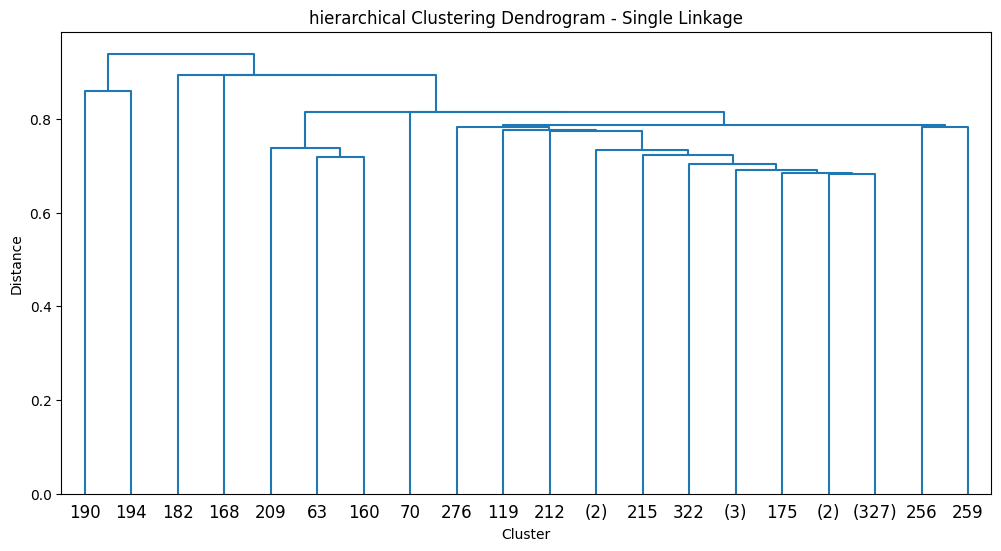

In [ ]:
plt.figure(figsize=(12,6))

dendrogram(
    Z,
    truncate_mode='lastp',
    p=20
)

plt.title("hierarchical Clustering Dendrogram - Single Linkage")
plt.xlabel("Cluster")
plt.ylabel("Distance")

plt.show()

In [ ]:
df['Cluster'] = fcluster(
    Z,
    t=4,
    criterion='maxclust'
)

print("\nFitness Data with Cluster:")

print(
    df[
        [
            'User_ID',
            'Daily_Steps',
            'Calories_Burned',
            'Workout_Duration',
            'Hours_Sleep',
            'Activity_Type',
            'Diet_Preference',
            'Gender',
            'Age_Group',
            'Cluster'
        ]
    ].head(20)
)



Fitness Data with Cluster:
   User_ID  Daily_Steps  Calories_Burned  Workout_Duration  Hours_Sleep  \
0    U0001        10426           966.47               101          7.2   
1    U0002        13459           855.07                43          7.5   
2    U0003         5298           303.72                14          8.4   
3    U0004         5841           842.68                52          5.2   
4    U0005         7343           708.11                35          8.6   
5    U0006         9604           667.96                39          9.0   
6    U0007         6772           816.76               101          8.1   
7    U0008        17116           822.05                12          5.6   
8    U0009        12133           673.36                36          4.8   
9    U0010        10740           738.37                26          6.6   
10   U0011         7570           887.84               111          8.9   
11   U0012         3138           477.82                32          6.5 

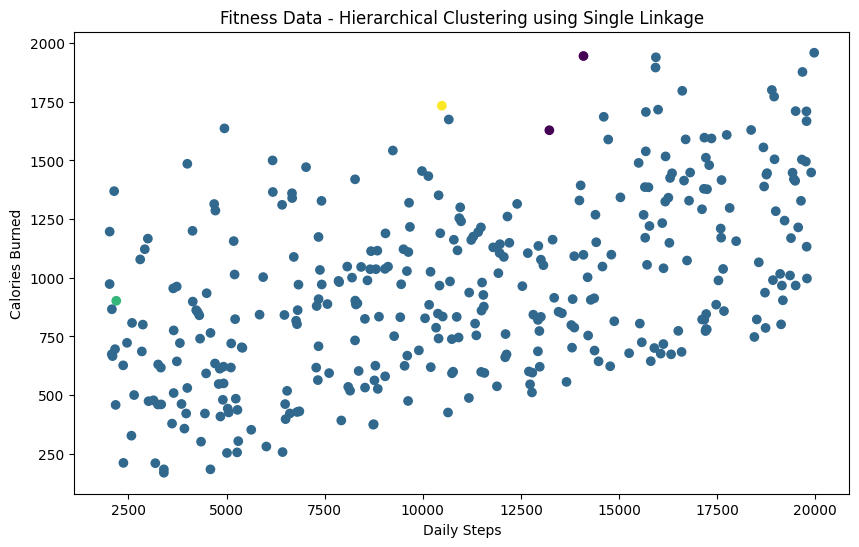

In [ ]:
plt.figure(figsize=(10,6))

plt.scatter(
    df['Daily_Steps'],
    df['Calories_Burned'],
    c=df['Cluster']

)

plt.xlabel('Daily Steps')
plt.ylabel('Calories Burned'),
plt.title('Fitness Data - Hierarchical Clustering using Single Linkage')

plt.show()
